<a href="https://colab.research.google.com/github/AMPeru12/EADA/blob/main/notebooks/00_colab_paso_a_paso_ejecutado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto EDA · Pipeline de data streams · Comercio electrónico (Google Colab)

Este notebook ejecuta el proyecto completo en orden. Cada paso indica **qué entregable o criterio de la rúbrica cubre**.

| Paso | Qué hace | Cubre |
|---|---|---|
| 1 | Conectar Drive y obtener el código | Repositorio |
| 2 | Preparar el stream de 10M desde el CSV de Kaggle | Dataset (sección 1 del informe) |
| 3 | Probar cada estructura frente a su versión exacta | Implementación |
| 4 | Ejecutar el pipeline de 10 etapas de punta a punta | Implementación (4 pts) · demo |
| 5 | Comparar algoritmos: cuál cumple el objetivo | Experimentación (4 pts) |
| 6 | Escalabilidad 1K–10M y gráfico log-log | Experimentación |
| 7 | Resumen de resultados para el informe y la PPT | Sección 7 · diapositiva 14 |
| 8 | Guardar resultados y subir a GitHub | Entregables |

**Antes de empezar:** sube a tu Google Drive, dentro de una carpeta `EDA`, el CSV de Kaggle (por ejemplo `2019-Oct.csv`) y, si aún no está en GitHub, el archivo `proyecto-eda-pipeline.zip`.
En Colab: *Entorno de ejecución → Cambiar tipo de entorno* → CPU con RAM alta si está disponible.

## Paso 1 · Conectar Google Drive y obtener el código

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE = '/content/drive/MyDrive/Proyecto EDA'          # carpeta donde subiste el CSV y el zip
CSV = f'{DRIVE}/2019-Oct.csv.zip'                # cambia el nombre si usas otro mes
import os
print('CSV encontrado:', os.path.exists(CSV))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV encontrado: True


In [ ]:
# Opción A: el código ya está en GitHub
REPO = 'https://github.com/AMPeru12/EADA.git'
!git clone -q $REPO /content/proyecto 2>/dev/null || echo "No se pudo clonar: usa la opción B"

# Opción B: descomprimir el zip desde Drive (si la opción A falló)
if not os.path.exists('/content/proyecto/src'):
    !unzip -q -o "$DRIVE/proyecto-eda-pipeline.zip" -d /content/ && mv /content/proyecto-eda-pipeline /content/proyecto

%cd /content/proyecto
!pip install -q -r requirements.txt
!ls

/content/proyecto
dashboard  docs		notebooks  requirements.txt  tests
data	   experiments	README.md  src


In [ ]:
import os, shutil
os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy('/content/drive/MyDrive/Proyecto EDA/kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)
!pip install -q kaggle
!kaggle datasets download -d mkechinov/ecommerce-behavior-data-from-multi-category-store -f 2019-Oct.csv -p "/content/drive/MyDrive/Proyecto EDA"
!ls -lh "/content/drive/MyDrive/Proyecto EDA"

Dataset URL: https://www.kaggle.com/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store
License(s): copyright-authors
100% 1.61G/1.61G [00:13<00:00, 132MB/s]

total 1.7G
-rw------- 1 root root 1.7G Dec  9  2019 2019-Oct.csv.zip
-rw------- 1 root root 9.2M Oct 30 16:22 Exposicion_Proyecto_EDA.pptx
-rw------- 1 root root   75 Oct 30 16:53 kaggle.json
-rw------- 1 root root 9.8M Oct 30 16:30 proyecto-eda-pipeline.zip
-rw------- 1 root root 320K Oct 30 16:22 Proyecto_Final_NombreGrupo.docx


## Paso 2 · Preparar el stream (dataset real + componente sintético)
El script toma los primeros N eventos del CSV (timestamps reales) y añade lo que el dataset no trae (supuestos S2–S9
del informe): tipo de orden, medio de pago y dispositivo, fraude y pagos rechazados, búsquedas, stock inicial,
~1% de duplicados, ~0.5% de registros inválidos y ~1% de eventos que llegan tarde.
**Empieza con 1M** para revisar; después genera los 10M (necesita ~6–8 GB de RAM).

In [ ]:
N = 10_000_000         # luego cambia a 10_000_000
!python src/preparar_datos.py --input "$CSV" --n $N --out data

Leyendo 10,000,000 eventos de /content/drive/MyDrive/Proyecto EDA/2019-Oct.csv.zip ...
/content/proyecto/src/preparar_datos.py:125: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, busq], ignore_index=True)
{
  "eventos_totales": 10559920,
  "eventos_reales": 10000000,
  "eventos_sinteticos": {
    "rafagas_fraude": 139178,
    "busquedas": 265994,
    "duplicados": 104052,
    "invalidos": 50696,
    "llegan_tarde": 105192
  },
  "rango_temporal": [
    "2019-09-30 23:59:55.553278795",
    "2019-10-08 17:27:41.912560032"
  ],
  "distribucion_event_type_%": {
    "view": 96.28,
    "cart": 1.99,
    "purchase": 1.73
  },
  "usuarios_unicos": 1070614,
  "productos_unicos": 121903,
  "sesiones_unicas": 2148765,
  "categorias_

In [ ]:
import json
resumen = json.load(open('data/eda_resumen.json', encoding='utf-8'))
resumen

{'eventos_totales': 10559920,
 'eventos_reales': 10000000,
 'eventos_sinteticos': {'rafagas_fraude': 139178,
  'busquedas': 265994,
  'duplicados': 104052,
  'invalidos': 50696,
  'llegan_tarde': 105192},
 'rango_temporal': ['2019-09-30 23:59:55.553278795',
  '2019-10-08 17:27:41.912560032'],
 'distribucion_event_type_%': {'view': 96.28, 'cart': 1.99, 'purchase': 1.73},
 'usuarios_unicos': 1070614,
 'productos_unicos': 121903,
 'sesiones_unicas': 2148765,
 'categorias_unicas': 566,
 'category_code_nulo_%': 32.24,
 'brand_nulo_%': 13.88,
 'compras': 172826,
 'pagos_rechazados': 23243,
 'ordenes (sesiones con compra)': 145986,
 'ordenes con >=2 productos (aristas del grafo)': 11502,
 'usuarios_fraudulentos': 5353,
 'fraudulentos_en_lista_negra': 2676,
 'entidades_en_lista_negra': 11101,
 'productos_sin_stock_inicial': 6367,
 'carritos_por_usuario_10min_p99.9': 17.0,
 'compras_por_usuario_10min_p99.9': 5.0,
 'semilla': 42,
 'segundos': 88.4}

**Revisa dos valores, porque definen decisiones de diseño (anótalos en el informe):**
- `ordenes con >=2 productos`: si son pocas, el grafo de co-compra se completa con carritos (el pipeline lo hace solo).
- `carritos/compras por usuario 10min p99.9`: sirve para justificar el umbral del Count-Min Sketch (15 carritos y 5 compras por defecto).

## Paso 3 · Probar las estructuras (cada una contra su versión exacta)

In [ ]:
!python -m pytest tests -q

...............                                                          [100%]
15 passed in 3.53s


In [ ]:
!sed -i 's/"umbral_cart": 15, "umbral_compra": 5,/"umbral_cart": 18, "umbral_compra": 6,/' src/pipeline.py
!grep -n '"umbral_cart"' src/pipeline.py

296:                    "umbral_cart": 18, "umbral_compra": 6, "umbral_rechazos": 3, "ventana_seg": 600,
303:        self.filtro = FiltroFraude(entidades_lista_negra, c["ventana_seg"], c["umbral_cart"], c["umbral_compra"],


## Paso 4 · Pipeline de punta a punta (demo)
Un evento atraviesa las 10 etapas: cola → limpieza → heap → Bloom/Count-Min → almacenamiento → B+Tree → servicio.
Cada cierto número de eventos (micro-lote) se refrescan KD-Tree, MinHash+LSH, HNSW y el grafo, así que las
recomendaciones cambian mientras llega el stream. Con 1M eventos tarda unos 10–20 minutos en Colab.

In [ ]:
STREAM = 'data/stream_10M.parquet'
# Prueba rápida con 200_000; para los resultados del informe usa 1_000_000 (o 10_000_000 si la RAM alcanza)
N_PIPELINE = 1_000_000
!python -m src.pipeline --stream $STREAM --blacklist data/blacklist.csv --stock data/catalogo_stock.csv --n $N_PIPELINE --out outputs/resultados.json

Procesando 1,000,000 eventos (refresco de índices cada 250,000)...
{
  "eventos_ingestados": 1000000,
  "preprocesamiento": {
    "invalidos": 6677,
    "invalidos_por_motivo": {
      "precio_invalido": 3409,
      "tipo_desconocido": 1602,
      "sesion_vacia": 1666
    },
    "duplicados_eliminados": 10227,
    "tardios_procesados": 8416,
    "tardios_fuera_de_ventana_cms": 79
  },
  "tiempos_seg": {
    "etapas por evento": 42.79,
    "5 KD-Tree": 0.84,
    "7 MinHash+LSH": 14.99,
    "7 SVD+HNSW": 35.28,
    "8 Grafo y PageRank": 0.07,
    "9 Trie (catálogo)": 0.02,
    "8 Comunidades": 3.01
  }
}
Alertas por motivo: {'pago_rechazado': 957, 'lista_negra': 8327, 'card_testing': 162, 'intensidad': 258} | precisión fraude: 0.997
Refrescos por micro-lote: [(250000, 33968, 13173), (500000, 46964, 1174), (750000, 56311, 1633), (1000000, 63635, 1991), (1000000, 63635, 1991)]

Traza de un evento de punta a punta:
  [0 Ingesta] compra express del producto 1002532 entra a la cola FIFO
  [1 

In [ ]:
import pandas as pd
r = json.load(open('outputs/resultados.json', encoding='utf-8'))
print('Preprocesamiento (inválidos, duplicados, tardíos):', r['preprocesamiento'])
print('Atendidos por prioridad (0 alerta · 1 express · 2 estándar · 3 programada · 4 carrito/búsqueda · 5 vista):')
print(r['atendidos_por_nivel_heap'])
print('\nAlertas por motivo:', r['alertas']['por_motivo'])
print('Precisión de las alertas de fraude frente al fraude inyectado:', r['alertas']['precision_fraude_vs_inyectado'])
pd.DataFrame(r['traza_evento'])

Preprocesamiento (inválidos, duplicados, tardíos): {'invalidos': 6677, 'invalidos_por_motivo': {'precio_invalido': 3409, 'tipo_desconocido': 1602, 'sesion_vacia': 1666}, 'duplicados_eliminados': 10227, 'tardios_procesados': 8416, 'tardios_fuera_de_ventana_cms': 79}
Atendidos por prioridad (0 alerta · 1 express · 2 estándar · 3 programada · 4 carrito/búsqueda · 5 vista):
{'0': 9704, '1': 3028, '2': 12895, '3': 3177, '4': 49814, '5': 914182}

Alertas por motivo: {'pago_rechazado': 957, 'lista_negra': 8327, 'card_testing': 162, 'intensidad': 258}
Precisión de las alertas de fraude frente al fraude inyectado: 0.997


,etapa,detalle
0,0 Ingesta,compra express del producto 1002532 entra a la...
1,1 Preprocesamiento,"pasa la validación, la normalización y la dedu..."
2,2 Heap,"se atiende con prioridad 1 (express), antes qu..."
3,6 Filtrado,Bloom Filter: entidades no señaladas · pago ap...
4,3 Almacenamiento,"actualiza ficha, stock (quedan 5), matriz usua..."
5,4 B+Tree,"producto indexado por (categoría, precio = 642..."
6,5/7/8 Micro-lote,"KD-Tree, MinHash+LSH, HNSW y grafo se actualiz..."
7,9 Servicio,recomendaciones Top-5 para el producto 1002532...


**Refrescos por micro-lote:** cómo evolucionan los índices y la recomendación del producto seguido.

In [ ]:
pd.DataFrame(r['refrescos_micro_lote'])

,eventos,final,productos,lsh_actualizados,lsh_indexados,hnsw,aristas_grafo,top3_pagerank,segundos,recomendacion_co_compra_producto_seguido
0,250000,False,33968,6027,6027,5000,13173,"[1004856, 1004767, 1005115]",7.15,"[4804056, 1004856, 4803107, 4804055, 26005003]"
1,500000,False,46964,10938,11084,5000,1174,"[1004856, 1004767, 1002544]",10.52,"[4804056, 4802036, 1004856, 4804055, 1005115]"
2,750000,False,56311,14324,15137,5000,1633,"[1004856, 1004767, 1005115]",12.02,"[4804056, 1004856, 4802036, 1005115, 4804055]"
3,1000000,False,63635,17181,18921,5000,1991,"[1004856, 1004767, 1005115]",14.04,"[4804056, 1005115, 1004856, 4802036, 1004767]"
4,1000000,True,63635,0,18921,5000,1991,"[1004856, 1004767, 1005115]",10.49,"[4804056, 1005115, 1004856, 4802036, 1004767]"


In [ ]:
print('Búsquedas más frecuentes:', r['busquedas']['top10'])
print('Autocompletado:', r['autocompletar_ejemplo'])
print('Productos disponibles por rango de precio:', r['rango_ejemplo'])
print('Top-10 más vendidos:', r['top10_mas_vendidos'])
r['recomendacion_ejemplo']

Búsquedas más frecuentes: [['smartphone', 4195], ['apple', 2905], ['samsung', 2745], ['xiaomi', 1376], ['clocks', 589], ['huawei', 483], ['headphone', 452], ['lucente', 342], ['refrigerators', 309], ['notebook', 302]]
Autocompletado: {'sm': ['smartphone', 'smeg', 'smart', 'smile', 'smashbox']}
Productos disponibles por rango de precio: {'category_id': 2053013553375346967, 'precio': [50, 200], 'productos_disponibles': [5100355, 5100817, 5100818, 5100181, 5100182, 5100183, 5100184, 5100859, 5100725, 5100726]}
Top-10 más vendidos: [[1004856, 696], [1004767, 493], [1005115, 290], [4804056, 281], [1004870, 256], [1002544, 255], [1004833, 230], [1004249, 190], [5100816, 181], [1002524, 156]]


{'producto': {'product_id': 1002532,
  'category_id': 2053013555631882655,
  'category_code': 'electronics.smartphone',
  'brand': 'apple',
  'price': 591.78,
  'stock': 0,
  'view': 275,
  'cart': 9,
  'purchase': 11},
 'similares_comportamiento_lsh': [1003363, 45600297],
 'complementarios_hnsw': [1002535, 1002528, 1003363, 18000903, 3700986],
 'co_compra_ppr': [4804056, 1005115, 1004856, 4802036, 1004767],
 'atributos_knn_exacto': [1801849, 1002540, 1306359, 1002542, 1004252]}

## Paso 5 · Comparar algoritmos: ¿cuál cumple el objetivo?
El enunciado exige elegir una opción en cada familia y **justificarla con evidencia** frente a una alternativa exacta o
más simple. Aquí se simulan las alternativas sobre los mismos datos y se aplica un criterio explícito de aceptación.

| Familia | Opciones que se comparan | Criterio para "cumple" |
|---|---|---|
| Filtrado | Bloom Filter vs set exacto · Count-Min vs diccionario | FP ≤ 1.5% y error ≤ ε·N, con mucha menos memoria |
| Similitud de conjuntos | MinHash+LSH (varias configuraciones) vs Jaccard por fuerza bruta | recall ≥ 0.8 y más rápido |
| ANN | HNSW (ef = 10, 50, 100) vs KD-Tree vs fuerza bruta | recall@10 ≥ 0.9 y menor tiempo de consulta |
| Ranking | PageRank vs grado | aporta un orden distinto (Spearman < 1) |
| Comunidades | Louvain vs Label Propagation | mayor modularidad con estabilidad (NMI) aceptable |

In [ ]:
import sys, time, tracemalloc, numpy as np
sys.path.insert(0, '/content/proyecto')
from src.estructuras.bloom import BloomFilter
from src.estructuras.countmin import CountMinSketch
from collections import Counter

df = pd.read_parquet(STREAM) if STREAM.endswith('.parquet') else pd.read_pickle(STREAM)
usuarios = df['user_id'].astype(str).unique()[:200_000]
print('Usuarios reales usados como claves:', len(usuarios))

# --- 5.1 Bloom Filter vs set: distintas tasas objetivo ---
filas = []
ausentes = [f'no_{i}' for i in range(100_000)]
for p in (0.05, 0.01, 0.001):
    tracemalloc.start(); t = time.perf_counter()
    b = BloomFilter(len(usuarios), p)
    for u in usuarios: b.agregar(u)
    tb = time.perf_counter() - t; _, mem = tracemalloc.get_traced_memory(); tracemalloc.stop()
    fp = sum(x in b for x in ausentes) / len(ausentes)
    filas.append({'estructura': f'Bloom p={p}', 'k': b.k, 'memoria_MB': mem / 1e6, 'tiempo_s': tb, 'FP_medida': fp, 'cumple (FP<=1.5·p)': fp <= 1.5 * p})
tracemalloc.start(); t = time.perf_counter(); s = set(usuarios); ts = time.perf_counter() - t
_, mem = tracemalloc.get_traced_memory(); tracemalloc.stop()
filas.append({'estructura': 'set exacto', 'k': None, 'memoria_MB': mem / 1e6, 'tiempo_s': ts, 'FP_medida': 0.0, 'cumple (FP<=1.5·p)': True})
os.makedirs('experiments/resultados', exist_ok=True)
t51 = pd.DataFrame(filas); t51.to_csv('experiments/resultados/comparacion_bloom.csv', index=False); t51

Usuarios reales usados como claves: 200000


,estructura,k,memoria_MB,tiempo_s,FP_medida,cumple (FP<=1.5·p)
0,Bloom p=0.05,4.0,0.158953,3.978743,0.04998,True
1,Bloom p=0.01,7.0,0.240581,5.495249,0.01078,True
2,Bloom p=0.001,10.0,0.360505,7.045146,0.00087,True
3,set exacto,NaN,12.584081,0.079278,0.00000,True


In [ ]:
# --- 5.2 Count-Min Sketch vs diccionario: frecuencia de eventos de carrito por usuario ---
claves = df.loc[df['event_type'] == 'cart', 'user_id'].astype(str).tolist()
filas = []
for eps in (0.01, 0.001):
    cms = CountMinSketch(epsilon=eps, delta=0.01)
    t = time.perf_counter()
    for k in claves: cms.agregar(k)
    tc = time.perf_counter() - t
    exacto = Counter(claves)
    err = np.array([cms.estimar(k) - v for k, v in list(exacto.items())[:20_000]])
    filas.append({'estructura': f'CMS eps={eps}', 'memoria_MB': cms.memoria_bytes() / 1e6, 'tiempo_s': tc,
                  'error_medio': err.mean(), 'error_max': err.max(), 'cota eps·N': eps * len(claves),
                  'cumple (error_max <= eps·N)': err.max() <= eps * len(claves)})
filas.append({'estructura': 'dict exacto', 'memoria_MB': sys.getsizeof(exacto) / 1e6, 'tiempo_s': None, 'error_medio': 0, 'error_max': 0})
t52 = pd.DataFrame(filas); t52.to_csv('experiments/resultados/comparacion_countmin.csv', index=False); t52

,estructura,memoria_MB,tiempo_s,error_medio,error_max,cota eps·N,cumple (error_max <= eps·N)
0,CMS eps=0.01,0.00544,1.987117,1011.39595,1278,3104.420,True
1,CMS eps=0.001,0.05438,1.755819,75.05400,167,310.442,True
2,dict exacto,3.84488,NaN,0.00000,0,NaN,NaN


In [ ]:
# --- 5.3 Similitud de conjuntos: configuraciones de MinHash+LSH vs fuerza bruta ---
from src.estructuras.minhash_lsh import MinHash, LSH, jaccard
vistas = df[df['event_type'].isin(['view', 'cart'])]
vistas = vistas.assign(sid=vistas['user_session'].astype('category').cat.codes)   # id entero estable de la sesión
ses = vistas.groupby('product_id')['sid'].apply(set)
ses = ses[ses.apply(len) >= 5].head(2000)           # 2000 productos: la fuerza bruta es O(n²)
ids, conjuntos = list(ses.index), list(ses.values)
UMBRAL = 0.125            # pares "similares": Jaccard ≥ 0.125, igual que la configuración del pipeline (sección 5.2)
t = time.perf_counter()
reales = {(i, j) for i in range(len(ids)) for j in range(i + 1, len(ids)) if jaccard(conjuntos[i], conjuntos[j]) >= UMBRAL}
t_bruta = time.perf_counter() - t
filas = [{'metodo': 'Jaccard fuerza bruta', 'tiempo_s': t_bruta, 'pares': len(reales), 'recall': 1.0, 'precision': 1.0}]
for perm, bandas in ((128, 16), (128, 32), (128, 64), (256, 128)):
    mh = MinHash(perm); firmas = [mh.firma(c) for c in conjuntos]
    t = time.perf_counter()
    l = LSH(perm, bandas)
    for i, f in enumerate(firmas): l.insertar(i, f)
    cand = {(min(i, j), max(i, j)) for i in range(len(ids)) for j in l.candidatos(firmas[i], excluir=i)}
    hall = {p for p in cand if jaccard(conjuntos[p[0]], conjuntos[p[1]]) >= UMBRAL}
    tl = time.perf_counter() - t
    rec = len(hall) / len(reales) if reales else 1.0
    filas.append({'metodo': f'MinHash+LSH k={perm} b={bandas} (umbral≈{l.umbral():.2f})', 'tiempo_s': tl, 'pares': len(hall),
                  'recall': rec, 'precision': len(hall) / len(cand) if cand else 1.0, 'cumple (recall>=0.8)': rec >= 0.8})
t53 = pd.DataFrame(filas); t53.to_csv('experiments/resultados/comparacion_lsh.csv', index=False); t53

,metodo,tiempo_s,pares,recall,precision,cumple (recall>=0.8)
0,Jaccard fuerza bruta,181.418186,154,1.000000,1.000000,NaN
1,MinHash+LSH k=128 b=16 (umbral≈0.71),0.103445,0,0.000000,1.000000,False
2,MinHash+LSH k=128 b=32 (umbral≈0.42),0.076228,3,0.019481,0.500000,False
3,MinHash+LSH k=128 b=64 (umbral≈0.12),0.558557,119,0.772727,0.042020,False
4,MinHash+LSH k=256 b=128 (umbral≈0.09),1.519125,147,0.954545,0.030895,True


> **Cómo leer esta tabla:** más bandas bajan el umbral y suben el recall, a costa de más candidatos falsos
> (menor precisión) y más tiempo. El pipeline y el informe usan k=128, b=64. Si esa fila no cumple recall ≥ 0.8
> y otra sí (por ejemplo k=256, b=128), cambia `num_perm` y `bandas_lsh` en `src/pipeline.py` y actualiza la
> sección 5.2 y la tabla de parámetros del informe. Los candidatos falsos no llegan al usuario porque se verifican
> con Jaccard exacto.

In [ ]:
%cd /content/proyecto
!git checkout -- . && git pull -q origin main
!grep -n '"num_perm"' src/pipeline.py

/content/proyecto
297:                    "refresco_eventos": 1_000_000, "min_sesiones_lsh": 5, "num_perm": 256, "bandas_lsh": 128,
308:        self.minhash = MinHash(c["num_perm"])
309:        self.lsh = LSH(c["num_perm"], c["bandas_lsh"])   # 128 bandas × 2 filas: umbral ≈ 0.088 (elegido en el paso 5.3)


In [ ]:
# --- 5.4 ANN: HNSW con distintos ef vs KD-Tree vs fuerza bruta (embeddings SVD de la matriz usuario-producto) ---
import scipy.sparse as sp
from scipy.sparse.linalg import svds
from src.estructuras.hnsw import HNSW, knn_coseno_exacto, recall_at_k
from src.estructuras.kdtree import KDTree
sub = df[~df['synthetic']].head(1_000_000)
u = sub['user_id'].astype('category').cat.codes; p = sub['product_id'].astype('category').cat.codes
M = sp.coo_matrix((np.ones(len(sub)), (u, p))).tocsr()
_, sv, Vt = svds(M.astype(float), k=32)
X = (Vt.T * sv).astype(np.float32)
pop = np.asarray(M.sum(axis=0)).ravel(); X = X[np.argsort(-pop)[:5000]]   # 5000 productos más populares
Xn = X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)
Q = Xn[np.random.default_rng(42).choice(len(Xn), 100, replace=False)]
exactos = [knn_coseno_exacto(Xn, q, 10) for q in Q]
t = time.perf_counter(); [knn_coseno_exacto(Xn, q, 10) for q in Q]; t_bruta = time.perf_counter() - t
filas = [{'metodo': 'Fuerza bruta (exacto)', 'tiempo_100_consultas_s': t_bruta, 'recall@10': 1.0}]
kd = KDTree(Xn); t = time.perf_counter(); res = [kd.knn(q, 10) for q in Q]; t_kd = time.perf_counter() - t
filas.append({'metodo': 'KD-Tree (exacto, 32 dim)', 'tiempo_100_consultas_s': t_kd,
              'recall@10': np.mean([recall_at_k([(d, i) for d, i in r_], e) for r_, e in zip(res, exactos)])})
h = HNSW(32, M=16, ef_construction=100)
for v in Xn: h.insertar(v)
for ef in (10, 50, 100):
    t = time.perf_counter(); res = [h.buscar(q, 10, ef) for q in Q]; th = time.perf_counter() - t
    rec = np.mean([recall_at_k(r_, e) for r_, e in zip(res, exactos)])
    filas.append({'metodo': f'HNSW ef={ef}', 'tiempo_100_consultas_s': th, 'recall@10': rec, 'cumple (recall>=0.9)': rec >= 0.9})
t54 = pd.DataFrame(filas); t54.to_csv('experiments/resultados/comparacion_ann.csv', index=False); t54

,metodo,tiempo_100_consultas_s,recall@10,cumple (recall>=0.9)
0,Fuerza bruta (exacto),0.045635,1.000,NaN
1,"KD-Tree (exacto, 32 dim)",1.624395,1.000,NaN
2,HNSW ef=10,0.024745,0.966,True
3,HNSW ef=50,0.063903,0.997,True
4,HNSW ef=100,0.107082,0.998,True


> Con 5,000 productos la fuerza bruta vectorizada de NumPy puede ser más rápida que HNSW escrito en Python puro.
> La ventaja de HNSW aparece al crecer n: el Paso 6 mide la escalabilidad hasta 100K vectores. Explica este matiz
> en el informe; es justo el tipo de análisis que se evalúa.

In [ ]:
# --- 5.5 Grafo: PageRank vs grado y Louvain vs Label Propagation (sobre el grafo real del pipeline) ---
g = r['grafo']
print('Fuente del grafo:', g['fuente'], '| nodos:', g['nodos'], '| aristas:', g['aristas'])
print('Spearman PageRank vs grado:', g['spearman_pagerank_vs_grado'])
print('Top-10 PageRank:', g['top10_pagerank']); print('Top-10 grado:   ', g['top10_grado'])
pd.DataFrame(g['comunidades']).T

Fuente del grafo: compras | nodos: 1702 | aristas: 1991
Spearman PageRank vs grado: 0.322
Top-10 PageRank: [1004856, 1004767, 1005115, 1002544, 1004833, 1004870, 1004873, 1002633, 1004249, 1004750]
Top-10 grado:    [1004856, 1004767, 1005115, 1002544, 1004833, 1004870, 1002633, 1004873, 1004750, 1004249]


,modularidad,segundos,n_comunidades,tam_max,tam_mediana,estabilidad_nmi
louvain,0.8450,0.0698,480.0,182.0,2.0,0.980
label_propagation,0.7782,0.0739,563.0,68.0,2.0,0.975


## Paso 6 · Escalabilidad 1K–10M (tiempo, memoria y gráfico log-log)
Mide cada estructura con 100 repeticiones hasta 10K (menos para tamaños mayores; el CSV registra cuántas) y guarda
`benchmark.csv`, `plataforma.json` y `escalabilidad_loglog.png`. **Hasta 1M tarda unos 20–40 minutos**; 10M es opcional.

In [ ]:
!python experiments/benchmark.py --max 1000000 --reps 100

{"plataforma": "Linux-6.6.159+-x86_64-with-glibc2.39", "procesador": "x86_64", "python": "3.13.18", "semilla": 42, "tamanos": [1000, 10000, 100000, 1000000], "reps_base": 100}
bloom          construir              n=     1,000 reps=100      11.25 ms ±    4.90  mem=    0.00 MB  {"tasa_fp": 0.013, "fp_teorica": 0.01}
set_exacto     construir              n=     1,000 reps=100       0.07 ms ±    0.50  mem=    0.04 MB  {"tasa_fp": 0.0}
bloom          consultar_10k          n=     1,000 reps=100      12.78 ms ±    6.54
set_exacto     consultar_10k          n=     1,000 reps=100       0.07 ms ±    0.22
count_min      insertar               n=     1,000 reps=100      11.78 ms ±    5.00  mem=    0.06 MB  {"error_medio": 0.0, "error_max": 0, "cota_eps_N": 1.0}
dict_exacto    insertar               n=     1,000 reps=100       0.06 ms ±    0.04  mem=    0.01 MB  {"error_medio": 0}
heap           insertar+extraer       n=     1,000 reps=100       1.43 ms ±    0.17  mem=    0.03 MB
bplustree      i

**Opcional · 10M (sección 6 del informe):** agrega el tamaño 10M para el filtrado y las estructuras base. Tarda bastante
más y necesita RAM alta; si Colab se queda sin memoria, reporta hasta 1M y explícalo en el informe.

In [ ]:
# !python experiments/benchmark.py --max 10000000 --reps 100   # quita el # para ejecutarlo

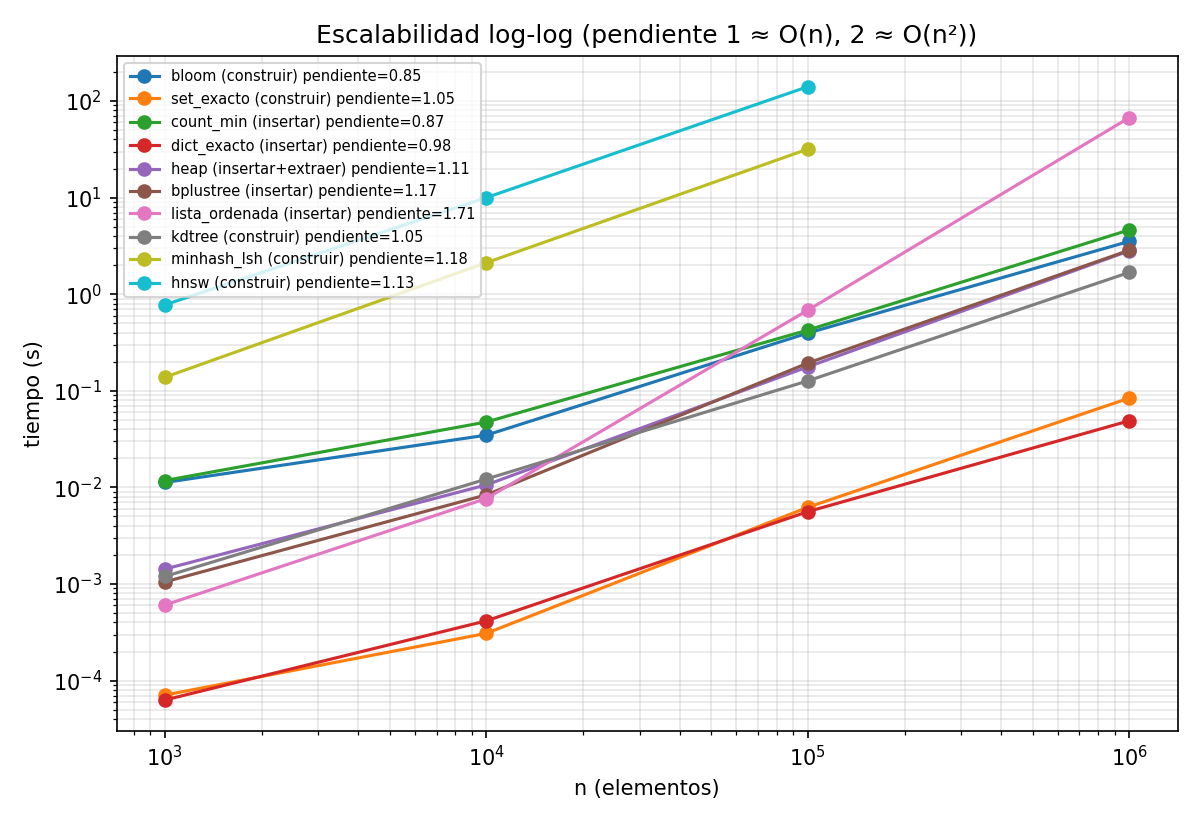

,estructura,operacion,n,reps,media_s,std_s,memoria_pico_bytes,tasa_fp,fp_teorica,error_medio,error_max,cota_eps_N,altura,pares,evaluacion,umbral_jaccard,precision_candidatos,recall,recall_at_10
0,bloom,construir,1000,100,0.011248,0.004897,2209.0,0.013,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,set_exacto,construir,1000,100,0.000071,0.000503,41224.0,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,bloom,consultar_10k,1000,100,0.012782,0.006536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,set_exacto,consultar_10k,1000,100,0.000073,0.000225,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,count_min,insertar,1000,100,0.011781,0.005004,56180.0,NaN,NaN,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78,bplustree,buscar_1000,1000000,3,0.003290,0.000647,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,bplustree,rango_1%,1000000,3,0.017961,0.010343,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
80,kdtree,construir,1000000,3,1.681317,0.013860,53401288.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
81,kdtree,knn10_x100,1000000,3,0.036138,0.003737,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
import os, pandas as pd
from IPython.display import Image, display
os.chdir('/content/proyecto')
b = pd.read_csv('experiments/resultados/benchmark.csv')
display(Image('experiments/resultados/escalabilidad_loglog.png'))
b

## Paso 7 · Resumen de resultados para el informe y la presentación
Junta todo en `outputs/resumen_para_informe.md`, ordenado como las tablas 7.1 a 7.6 del informe y la columna
"Resultado" de la diapositiva 14. Copia esos valores en las celdas amarillas del Word y en la PPT.

In [ ]:
!python experiments/resumen_informe.py > /dev/null
from IPython.display import Markdown
Markdown(open('outputs/resumen_para_informe.md', encoding='utf-8').read())

# Resultados para completar el informe y la presentación

**Plataforma (sección 6):** Linux-6.6.159+-x86_64-with-glibc2.39 · procesador: x86_64 · Python 3.13.18 · semilla 42

## Tabla 7.1 · Filtrado probabilístico frente a estructuras exactas

| n | Bloom: tiempo / memoria | Set exacto: tiempo / memoria | Tasa FP (teórica 1%) | CMS: error promedio | Dict exacto: memoria |
|---|---|---|---|---|---|
| 1K | 11.2 ms / 0.00 MB | 0.1 ms / 0.04 MB | 1.30% | 0.000 | 0.01 MB |
| 10K | 34.7 ms / 0.01 MB | 0.3 ms / 0.66 MB | 1.07% | 0.001 | 0.06 MB |
| 100K | 396.0 ms / 0.12 MB | 6.2 ms / 6.29 MB | 0.98% | 1.371 | 0.44 MB |
| 1M | 3,523.1 ms / 1.20 MB | 84.1 ms / 50.33 MB | 0.97% | 25.637 | 3.94 MB |

## Tabla 7.2 · MinHash+LSH y HNSW frente a métodos exactos

| n | LSH: tiempo | Fuerza bruta Jaccard: tiempo | LSH: precisión / recall | HNSW (ef=50): tiempo / recall@10 | KNN exacto: tiempo |
|---|---|---|---|---|---|
| 1K | 138.2 ms | 2,110.7 ms (todos los pares) | 0.860 / 0.999 | 44.7 ms / 1.000 | 8.9 ms |
| 10K | 2,118.5 ms | 7,548.9 ms (muestra de 300 consultas) | 0.403 / 1.000 | 48.9 ms / 0.932 | 56.1 ms |
| 100K | 31,764.5 ms | 72,452.6 ms (muestra de 300 consultas) | 0.064 / 1.000 | 57.0 ms / 0.862 | 898.8 ms |

Tiempos de HNSW y KNN exacto: 100 consultas de 10 vecinos. KD-Tree en 32 dimensiones (5.3):

| n | KD-Tree 32d: tiempo | KD-Tree recall@10 | HNSW ef=10 | HNSW ef=100 |
|---|---|---|---|---|
| 1K | 61.6 ms | 1.000 | 19.5 ms | 48.0 ms |
| 10K | 834.8 ms | 1.000 | 22.3 ms | 62.7 ms |
| 100K | 7,052.4 ms | 1.000 | 31.2 ms | 82.5 ms |

## 7.5 · Escalabilidad

Insertar la imagen `experiments/resultados/escalabilidad_loglog.png`. Pendientes medidas:

| Estructura | Pendiente log-log |
|---|---|
| bloom (construir) | 0.85 |
| count_min (insertar) | 0.87 |
| heap (insertar+extraer) | 1.11 |
| bplustree (insertar) | 1.17 |
| lista_ordenada (insertar) | 1.71 |
| kdtree (construir) | 1.05 |
| minhash_lsh (construir) | 1.18 |
| hnsw (construir) | 1.13 |

## Comparación de configuraciones con datos reales (Colab, paso 5)

**bloom**

| estructura    |   k |   memoria_MB |   tiempo_s |   FP_medida | cumple (FP<=1.5·p)   |
|:--------------|----:|-------------:|-----------:|------------:|:---------------------|
| Bloom p=0.05  |   4 |       0.159  |    3.979   |     0.04998 | True                 |
| Bloom p=0.01  |   7 |       0.2406 |    5.495   |     0.01078 | True                 |
| Bloom p=0.001 |  10 |       0.3605 |    7.045   |     0.00087 | True                 |
| set exacto    | nan |      12.58   |    0.07928 |     0       | True                 |

**countmin**

| estructura    |   memoria_MB |   tiempo_s |   error_medio |   error_max |   cota eps·N |   cumple (error_max <= eps·N) |
|:--------------|-------------:|-----------:|--------------:|------------:|-------------:|------------------------------:|
| CMS eps=0.01  |      0.00544 |      1.987 |       1011    |        1278 |       3104   |                             1 |
| CMS eps=0.001 |      0.05438 |      1.756 |         75.05 |         167 |        310.4 |                             1 |
| dict exacto   |      3.845   |    nan     |          0    |           0 |        nan   |                           nan |

**lsh**

| metodo                                |   tiempo_s |   pares |   recall |   precision |   cumple (recall>=0.8) |
|:--------------------------------------|-----------:|--------:|---------:|------------:|-----------------------:|
| Jaccard fuerza bruta                  |  181.4     |     154 |  1       |     1       |                    nan |
| MinHash+LSH k=128 b=16 (umbral≈0.71)  |    0.1034  |       0 |  0       |     1       |                      0 |
| MinHash+LSH k=128 b=32 (umbral≈0.42)  |    0.07623 |       3 |  0.01948 |     0.5     |                      0 |
| MinHash+LSH k=128 b=64 (umbral≈0.12)  |    0.5586  |     119 |  0.7727  |     0.04202 |                      0 |
| MinHash+LSH k=256 b=128 (umbral≈0.09) |    1.519   |     147 |  0.9545  |     0.0309  |                      1 |

**ann**

| metodo                   |   tiempo_100_consultas_s |   recall@10 |   cumple (recall>=0.9) |
|:-------------------------|-------------------------:|------------:|-----------------------:|
| Fuerza bruta (exacto)    |                  0.04564 |       1     |                    nan |
| KD-Tree (exacto, 32 dim) |                  1.624   |       1     |                    nan |
| HNSW ef=10               |                  0.02474 |       0.966 |                      1 |
| HNSW ef=50               |                  0.0639  |       0.997 |                      1 |
| HNSW ef=100              |                  0.1071  |       0.998 |                      1 |

## Tabla 7.3 · Grafo de co-compra

| Métrica | Louvain | Label Propagation |
|---|---|---|
| Modularidad Q | 0.845 | 0.7782 |
| Tiempo (s) | 0.0698 | 0.0739 |
| Número de comunidades | 480 | 563 |
| Tamaño mediano / máximo | 2.0 / 182 | 2.0 / 68 |
| Estabilidad (NMI promedio, 10 semillas) | 0.98 | 0.975 |

PageRank frente a grado: Spearman = **0.322**, productos en común en los Top-10 = **10**. Grafo: 1,702 nodos, 1,991 aristas, fuente: compras.

## Tabla 7.4 · Pipeline de punta a punta

| Métrica | Resultado |
|---|---|
| Eventos procesados | 1,000,000 |
| Registros inválidos descartados (por motivo) / duplicados / tardíos | 6,677 (precio_invalido: 3,409, tipo_desconocido: 1,602, sesion_vacia: 1,666) / 10,227 / 8,416 |
| Alertas por motivo: lista negra · intensidad · prueba de tarjetas · pago rechazado | 8,327 · 258 · 162 · 957 |
| Precisión de las alertas de fraude frente al fraude inyectado | 0.997 |
| Falsos positivos del Bloom Filter descartados en la verificación | 30,209 de 38,536 positivos |
| Tasa de aciertos de la caché LRU / productos agotados | 77.7% / 3,463 |
| Densidad de la matriz usuario-producto | 0.000060 (0.0060%) |
| Refrescos por micro-lote y cambio de la recomendación del producto seguido | 5 refrescos; la recomendación cambió en 3 de 4 transiciones |

## 7.6 · Traza de un evento

- **0 Ingesta:** compra express del producto 1002532 entra a la cola FIFO
- **1 Preprocesamiento:** pasa la validación, la normalización y la deduplicación
- **2 Heap:** se atiende con prioridad 1 (express), antes que estándar y vistas
- **6 Filtrado:** Bloom Filter: entidades no señaladas · pago aprobado · Count-Min Sketch bajo el umbral → aprobado
- **3 Almacenamiento:** actualiza ficha, stock (quedan 5), matriz usuario-producto y órdenes
- **4 B+Tree:** producto indexado por (categoría, precio = 642.69) para consultas por rango
- **5/7/8 Micro-lote:** KD-Tree, MinHash+LSH, HNSW y grafo se actualizan con el producto en cada refresco
- **9 Servicio:** recomendaciones Top-5 para el producto 1002532: {"similares_comportamiento_lsh": [1003363, 45600297], "complementarios_hnsw": [1002535, 1002528, 1003363, 18000903, 3700986], "co_compra_ppr": [4804056, 1005115, 1004856, 4802036, 1004767], "atributos_knn_exacto": [1801849, 1002540, 1306359, 1002542, 1004252]}

## Diapositiva 14 · columna Resultado

| Técnica | Resultado |
|---|---|
| Bloom Filter | FP = 0.97% a 1M → cumple |
| Count-Min Sketch | error máx. 118 ≤ ε·N = 1000 → cumple |
| MinHash + LSH | recall = 1.00 a 100K → cumple |
| HNSW | recall@10 = 0.86 (ef=50) a 100K → no cumple |
| PageRank | Spearman = 0.322 · 10/10 en común → aporta un orden distinto |
| Louvain | Q = 0.845 vs 0.7782 · NMI 0.98 vs 0.975 → cumple |


## Paso 8 · Guardar en Drive


In [ ]:
%cd /content/proyecto
DRIVE = '/content/drive/MyDrive/Proyecto EDA'
!mkdir -p "$DRIVE/resultados" && cp -r outputs experiments/resultados data/eda_resumen.json "$DRIVE/resultados/"
print('Copia de seguridad en', f'{DRIVE}/resultados')

/content
Copia de seguridad en /content/drive/MyDrive/Proyecto EDA/resultados
